# PathSnap: data processing and feature engineering
Run from the project root. This notebook inspects the 80 training and 10 student-test trips, builds candidate features, and exports weak labels separately. Reference route rows are not GPS-point labels.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from pipeline import *
ROOT=Path.cwd(); DATA=ROOT/'Student_folder'/'Student folder'; OUT=ROOT/'results'; CONFIG=Config()
assert (ROOT/'pipeline.py').exists()

## Dataset inventory and quality checks
Check GPS validity, timestamps, graph endpoints, connectivity, route continuity and partition sizes.

In [2]:
inv=inventory(DATA); inv.to_csv(OUT/'dataset_inventory.csv',index=False)
display(inv.groupby('partition')[['raw_observations','clean_observations','nodes','arcs','route_entries','invalid_observations','gap_count','route_breaks']].sum())
assert inv.status.eq('ok').all()
assert inv.groupby('partition').size().to_dict()=={'train':80,'student_test':10}

,raw_observations,clean_observations,nodes,arcs,route_entries,invalid_observations,gap_count,route_breaks
partition,,,,,,,,
student_test,19160,19160,90689,185041,3477,0,2,1
train,208417,208417,1933485,3876904,31336,0,133,13


## Preprocessing and features
GPS timestamps are stably sorted and duplicate times removed. Coordinates use local UTM metres. Candidate arcs retain original trip-local row IDs. Features use distance, geometry, heading, speed, time gaps and node degrees. No reference data enters feature generation.

In [3]:
trip=discover_trips(DATA,'train')[0]; track,audit=clean_track(trip); nodes,arcs=read_graph(trip); road=RoadIndex(nodes,arcs,CONFIG); candidates,observations=build_candidate_features(track,road,CONFIG)
display(pd.DataFrame(candidates['X'],columns=FEATURE_NAMES).describe().T)
print(audit, candidates['X'].shape)

,count,mean,std,min,25%,50%,75%,max
distance_m,10062.0,26.643255,21.276514,0.004101,10.727485,21.387466,36.846245,99.973763
arc_length_m,10062.0,134.350357,192.581604,0.420427,30.240166,70.133896,145.854713,1106.736694
projection_fraction,10062.0,0.499636,0.410359,0.000000,0.000000,0.498482,1.000000,1.000000
distance_to_start_m,10062.0,85.699646,118.895470,0.834542,26.029051,48.293697,93.545248,1108.079224
distance_to_end_m,10062.0,87.110901,124.791237,0.834542,26.035294,48.214174,94.543327,1173.245728
heading_cos,10062.0,0.077676,0.876968,-1.000000,-0.978493,0.150570,0.986604,1.000000
heading_sin,10062.0,0.002443,0.428067,-1.000000,-0.154487,0.000000,0.161235,1.000000
heading_valid,10062.0,0.958259,0.200007,0.000000,1.000000,1.000000,1.000000,1.000000
speed_mps,10062.0,37.772869,15.861854,0.000000,25.103704,40.992046,50.366707,72.416298
dt_s,10062.0,1.033393,0.456951,0.000000,1.000000,1.000000,1.000000,16.000000


{'raw_observations': 1315, 'invalid_observations': 0, 'duplicate_timestamps_removed': 0, 'original_nonincreasing_steps': 0, 'clean_observations': 1315} (10062, 19)


## Reference alignment
Monotone alignment derives weak observation labels from the supplied arc sequence. Residual thresholds identify usable labels. These are not independently verified pointwise ground truth.

In [4]:
route=read_reference(trip,len(arcs)); labels=align_reference(track,road,route,CONFIG); display(labels[['alignment_distance_m','nearest_reference_distance_m','label_usable']].describe()); assert np.all(np.diff(labels.route_position)>=0)

,alignment_distance_m,nearest_reference_distance_m
count,1315.000000,1315.000000
mean,5.029455,5.015346
std,3.786911,3.784794
min,0.004101,0.004101
25%,2.039634,2.030034
50%,4.297891,4.290264
75%,7.240192,7.190613
max,27.215523,27.215523


## GPS and road map
Blue shows GPS observations, green the supplied reference, and grey the road network. Predicted routes will be added after model training.

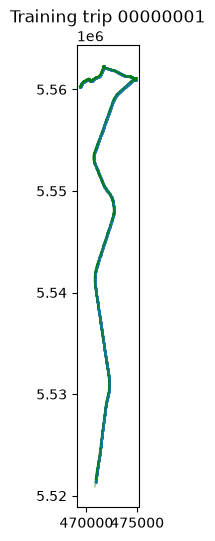

In [5]:
make_map(trip,OUT/'maps'/'training_trip_00000001.html'); xy=project(road.transformer,track[['longitude','latitude']].to_numpy()); fig,ax=plt.subplots(figsize=(9,6)); ax.plot(xy[:,0],xy[:,1],'.',ms=2,label='GPS'); rxy=road.xy[arcs[route]]; ax.plot(rxy[:,:,0].T,rxy[:,:,1].T,color='green',alpha=.35); ax.set_aspect('equal'); ax.set_title('Training trip 00000001'); fig.savefig(OUT/'figures'/'training_trip_00000001.png',dpi=150); plt.show()

## Export all permitted trips
Each trip receives candidates.npz, targets.npz, observations.csv.gz, labels.csv.gz and metadata.json. Candidate misses and weak-label coverage remain in the summary. No evaluator data is accessed.

In [6]:
summary=process_dataset(DATA,OUT/'processed',CONFIG); display(summary.groupby('partition')[['clean_observations','candidate_rows','no_candidate_observations','usable_label_observations','reference_candidate_misses','fit_rows']].sum()); summary.to_csv(OUT/'processing_summary.csv',index=False)

train: 10/80 trips processed


train: 20/80 trips processed


train: 30/80 trips processed


train: 40/80 trips processed


train: 50/80 trips processed


train: 60/80 trips processed


train: 70/80 trips processed


train: 80/80 trips processed


student_test: 10/10 trips processed


,clean_observations,candidate_rows,no_candidate_observations,usable_label_observations,reference_candidate_misses,fit_rows
partition,,,,,,
student_test,19160,130923,0,17646,36,118594
train,208417,1358538,1413,153683,968,1021740


## Trip-level cross-validation
All rows from a trip remain in one fold. Learned scaling must be fitted inside the training folds in the later model notebook.

In [7]:
ids=np.array([x.name for x in discover_trips(DATA,'train')]); fold=np.empty(len(ids),int)
for k,(_,v) in enumerate(KFold(n_splits=5,shuffle=True,random_state=42).split(ids)): fold[v]=k
pd.DataFrame({'trip_id':ids,'validation_fold':fold}).to_csv(OUT/'training_folds.csv',index=False)
print('Wrote five trip-level folds.')

Wrote five trip-level folds.


Next stages: train and compare five models, perform Bayesian tuning, then implement HMM/Viterbi, API and UI. Pointwise metrics must be described as agreement with derived weak labels.